# 09 ResNet50 Transfer Learning for Leaf Disease Classification (with SMOTE Support)

## Objective
Train ResNet50 with residual connections and SMOTE class balancing for 40-class crop leaf disease detection:
- Phase 1: Feature extraction with frozen residual backbone
- Phase 2: Progressive fine-tuning across residual stages
- Balanced data ingestion using SMOTE
- Evaluation, confusion matrices, and model serialization

**Prerequisites:** `01_data_check.ipynb`, `02_dataset_visualization.ipynb`, `03_targeted_augmentation.ipynb`, `04_data_preprocessing.ipynb`
**Next Step:** `10_efficientnetb0_training.ipynb`

## 1. Import Required Libraries

In [19]:
# Load preprocessed data using memory-efficient loader with SMOTE support
print("Loading preprocessed data with SMOTE support...\n")

data_base_path = r"D:\cnn_model\results\preprocessed_data_efficient"
BATCH_SIZE = CONFIG['batch_size']
USE_SMOTE = CONFIG.get('use_smote', True)

sys.path.insert(0, r"D:\cnn_model\utils")
from efficient_data_loader import create_train_val_test_datasets, get_class_weights, get_label_encoding

train_dataset, val_dataset, test_dataset, metadata = create_train_val_test_datasets(
    base_path=data_base_path,
    batch_size=BATCH_SIZE,
    use_smote=USE_SMOTE
)

num_classes = metadata['num_classes']
train_count = metadata['num_train']
val_count = metadata['num_val']
test_count = metadata['num_test']
label_encoding = metadata['label_encoding']
class_weights = get_class_weights(data_base_path, use_smote=USE_SMOTE)

print(f"✓ ResNet50 Data Pipeline Ready (SMOTE: {metadata.get('smote_enabled', False)})")
print(f"  Training Samples: {train_count} (~{metadata['batches_per_epoch']} batches/epoch)")
print(f"  Validation Samples: {val_count}")
print(f"  Test Samples: {test_count}")


TensorFlow version: 2.15.0
GPU Available: []


# Load preprocessed data using memory-efficient loader with SMOTE support
print("Loading preprocessed data with SMOTE support...\n")

data_base_path = r"D:\cnn_model\results\preprocessed_data_efficient"
BATCH_SIZE = CONFIG['batch_size']
USE_SMOTE = CONFIG.get('use_smote', True)

sys.path.insert(0, r"D:\cnn_model\utils")
from efficient_data_loader import create_train_val_test_datasets, get_class_weights, get_label_encoding

train_dataset, val_dataset, test_dataset, metadata = create_train_val_test_datasets(
    base_path=data_base_path,
    batch_size=BATCH_SIZE,
    use_smote=USE_SMOTE
)

num_classes = metadata['num_classes']
train_count = metadata['num_train']
val_count = metadata['num_val']
test_count = metadata['num_test']
label_encoding = metadata['label_encoding']
class_weights = get_class_weights(data_base_path, use_smote=USE_SMOTE)

print(f"✓ ResNet50 Data Pipeline Ready (SMOTE: {metadata.get('smote_enabled', False)})")
print(f"  Training Samples: {train_count} (~{metadata['batches_per_epoch']} batches/epoch)")
print(f"  Validation Samples: {val_count}")
print(f"  Test Samples: {test_count}")


In [20]:
# Configuration
CONFIG = {
    'input_shape': (224, 224, 3),
    'num_classes': 40,
        'batch_size': 8,
        'use_smote': True,            # SMOTE class balancing for all classes
    
    # Phase 1: Frozen base model (feature extraction)
    'phase1_epochs': 20,
    'phase1_learning_rate': 3e-4, # Slightly higher so the classification head learns faster
    
    # Phase 2: Fine-tuning (PROGRESSIVE unfreezing strategy - improved)
    'phase2_epochs': 15,              # 5 epochs stage 1 + 10 epochs stage 2
    'phase2_learning_rate': 5e-5,     # Higher for stable learning
    'num_unfreeze_layers': 15,        # Reduced to prevent overfitting
    'stage1_unfreeze_layers': 10,     # Progressive unfreezing stage 1
    'stage1_epochs': 5,               # Warm up with fewer layers
    'stage2_epochs': 10,              # Final stage with all unfrozen layers
    
    # Architecture (IMPROVED regularization)
    'dense_units': 128,
    'dropout_rate': 0.5,
    'optimizer': 'adam',
    
    # Directories (FIXED - use preprocessed_data_efficient)
    'data_dir': r'D:\cnn_model\results\preprocessed_data_efficient',
    'models_dir': r'D:\cnn_model\models\resnet50',
    'logs_dir': r'D:\cnn_model\results\logs',
    'plots_dir': r'D:\cnn_model\results\plots',
    'confusion_matrix_dir': r'D:\cnn_model\results\confusion_matrix'
}

# ============================================================================
# KEY OPTIMIZATIONS FOR IMPROVED ACCURACY (Section 2.1)
# ============================================================================
# Problem Fixed: Phase 2 fine-tuning previously degraded accuracy (6.09% vs 27.83% in Phase 1)
#
# Solutions Implemented:
# 1. Smaller Batch Size (16 → 8): Better generalization on small datasets with noisy gradients
# 2. Higher Learning Rates: 
#    - Phase 1: 1e-4 → 3e-4 (faster classification head learning)
#    - Phase 2: 5e-7 → 5e-5 (prevents fine-tuning stalling)
# 3. Fewer Unfrozen Layers (50 → 15): Prevents overfitting on limited data
# 4. Stronger Regularization:
#    - Dropout: 0.35 → 0.5 (reduces overfitting)
#    - L2 regularization on dense layers
# 5. CRITICAL ResNet50 Input Fix:
#    - Data range: [0, 1] → ResNet50 expects: [-1, 1]
#    - Conversion: 2.0 * x - 1.0 converts [0, 1] to [-1, 1]
#    - **Without this, model barely learns!**
# 6. Progressive Unfreezing: Stage 1 (10 layers, 5 epochs) → Stage 2 (15 layers, 10 epochs)
# 7. Memory Efficiency: Load NPZ files on-demand instead of full dataset in RAM
#
# Expected Result: Better accuracy and more stable training with proper resource utilization
# ============================================================================

# Create directories
os.makedirs(CONFIG['models_dir'], exist_ok=True)
os.makedirs(CONFIG['logs_dir'], exist_ok=True)
os.makedirs(CONFIG['plots_dir'], exist_ok=True)
os.makedirs(CONFIG['confusion_matrix_dir'], exist_ok=True)

print("Configuration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")

Configuration:
  input_shape: (224, 224, 3)
  num_classes: 40
  batch_size: 8
  phase1_epochs: 20
  phase1_learning_rate: 0.0003
  phase2_epochs: 15
  phase2_learning_rate: 5e-05
  num_unfreeze_layers: 15
  stage1_unfreeze_layers: 10
  stage1_epochs: 5
  stage2_epochs: 10
  dense_units: 128
  dropout_rate: 0.5
  optimizer: adam
  data_dir: D:\cnn_model\results\preprocessed_data_efficient
  models_dir: D:\cnn_model\models\resnet50
  logs_dir: D:\cnn_model\results\logs
  plots_dir: D:\cnn_model\results\plots
  confusion_matrix_dir: D:\cnn_model\results\confusion_matrix


In [21]:
# Load preprocessed data using memory-efficient loader with SMOTE support
print("Loading preprocessed data with SMOTE support...\n")

data_base_path = r"D:\cnn_model\results\preprocessed_data_efficient"
BATCH_SIZE = CONFIG['batch_size']
USE_SMOTE = CONFIG.get('use_smote', True)

sys.path.insert(0, r"D:\cnn_model\utils")
from efficient_data_loader import create_train_val_test_datasets, get_class_weights, get_label_encoding

train_dataset, val_dataset, test_dataset, metadata = create_train_val_test_datasets(
    base_path=data_base_path,
    batch_size=BATCH_SIZE,
    use_smote=USE_SMOTE
)

num_classes = metadata['num_classes']
train_count = metadata['num_train']
val_count = metadata['num_val']
test_count = metadata['num_test']
label_encoding = metadata['label_encoding']
class_weights = get_class_weights(data_base_path, use_smote=USE_SMOTE)

print(f"✓ ResNet50 Data Pipeline Ready (SMOTE: {metadata.get('smote_enabled', False)})")
print(f"  Training Samples: {train_count} (~{metadata['batches_per_epoch']} batches/epoch)")
print(f"  Validation Samples: {val_count}")
print(f"  Test Samples: {test_count}")


Loading preprocessed data using memory-efficient loader...

✓ Data directory verified: D:\cnn_model\results\preprocessed_data_efficient

✓ Number of classes: 40
  First 5 classes: ['Brinjal_Healthy', 'Brinjal_Early_Leaf_spot', 'Brinjal_Eggplant Wilt Disease', 'Brinjal_Leaf_curl', 'Brinjal_Little_leaf']...

✓ Dataset split:
  - Train: 6880 images
  - Val: 860 images
  - Test: 860 images

✓ One-hot encoded labels:
  - y_train shape: (6880, 40)
  - y_val shape: (860, 40)
  - y_test shape: (860, 40)

Creating TensorFlow datasets from individual NPZ files...
✓ Created TensorFlow datasets with batch_size=8:
  - train_dataset: 860 batches (approx.)
  - val_dataset: 108 batches (approx.)
  - test_dataset: 108 batches (approx.)

Loading validation and test dataset splits into memory...
  Loading X_val...
    ✓ X_val: (860, 224, 224, 3), range: [0.0000, 1.0000]
  Loading X_test...
    ✓ X_test: (860, 224, 224, 3), range: [0.0000, 1.0000]

✓ Val and Test datasets loaded - ready for training!



In [22]:
# Load class weights for training
print("Loading class weights...\n")

# Load precomputed class weights from preprocessing
weights_file_path = os.path.join(CONFIG['data_dir'], 'class_weights.json')

class_weight = {}

try:
    with open(weights_file_path, 'r') as f:
        class_weight_str_keys = json.load(f)
    
    class_weight = {int(k): v for k, v in class_weight_str_keys.items()}
    print(f"✓ Class weights loaded from preprocessing:")
    for class_idx, weight in class_weight.items():
        if class_idx < min(5, len(class_names)):  # Show first 5
            print(f"  - {class_names[class_idx]}: {weight:.4f}")
    if len(class_weight) > 5:
        print(f"  ... and {len(class_weight) - 5} more")
except FileNotFoundError:
    print(f"Warning: Could not find class weights file. Computing from y_train...")
    class_weight = compute_class_weights_from_labels(y_train, class_names=class_names, verbose=True)

print(f"\n✓ Class weights ready for training\n")


Loading class weights...

✓ Class weights loaded from preprocessing:
  - Brinjal_Healthy: 0.7414
  - Brinjal_Early_Leaf_spot: 0.6825
  - Brinjal_Eggplant Wilt Disease: 0.7288
  - Brinjal_Leaf_curl: 1.0750
  - Brinjal_Little_leaf: 1.0750
  ... and 35 more

✓ Class weights ready for training



## 2.1 Key Optimizations for Improved Accuracy

**See code comments in Section 2 above for detailed explanation of all 7 optimizations.**

Previous issue: Phase 2 fine-tuning degraded accuracy (6.09% vs 27.83%)  
**Fixed by:** Smaller batch size, higher learning rates, fewer unfrozen layers, stronger regularization, progressive unfreezing, and memory-efficient data loading.

**Result:** Improved accuracy with stable training and proper resource utilization.

In [23]:
# ============================================================================
# VERIFICATION: Data Loading Status
# ============================================================================
# This cell verifies that validation and test data are properly loaded
# NOTE: X_train is NOT loaded (uses generator for memory efficiency)

print("=" * 80)
print("DATA ARRAYS VERIFICATION")
print("=" * 80)

# Verify that X_val and X_test are in memory
if 'X_val' not in dir() or 'X_test' not in dir():
    raise RuntimeError("❌ ERROR: X_val or X_test not in memory!\n"
                      "Please run the previous cells to load the data.")

print("\n✓ Data Loading Status:")
print(f"  - X_val available: {X_val.shape}")
print(f"    Range: [{X_val.min():.4f}, {X_val.max():.4f}]")
print(f"  - X_test available: {X_test.shape}")
print(f"    Range: [{X_test.min():.4f}, {X_test.max():.4f}]")
print(f"  - y_val available: {y_val.shape}")
print(f"  - y_test available: {y_test.shape}")
print(f"  - train_dataset: Generator (memory-efficient, NOT loaded)")
print(f"  - val_dataset: Generator (consumed to create X_val)")
print(f"  - test_dataset: Generator (consumed to create X_test)")

print(f"\n✓ Class metadata:")
print(f"  - Num classes: {num_classes}")
print(f"  - Class names loaded: {len(class_names)}")
print(f"  - Class weights loaded: {len(class_weight)}")

print("\n" + "=" * 80)

DATA ARRAYS VERIFICATION

✓ Data Loading Status:
  - X_val available: (860, 224, 224, 3)
    Range: [0.0000, 1.0000]
  - X_test available: (860, 224, 224, 3)
    Range: [0.0000, 1.0000]
  - y_val available: (860, 40)
  - y_test available: (860, 40)
  - train_dataset: Generator (memory-efficient, NOT loaded)
  - val_dataset: Generator (consumed to create X_val)
  - test_dataset: Generator (consumed to create X_test)

✓ Class metadata:
  - Num classes: 40
  - Class names loaded: 40
  - Class weights loaded: 40



## 3. Build ResNet50 Model with Custom Classification Head

**Architecture Details:**
- **Base Model**: ResNet50 with ImageNet pretrained weights
- **Input**: 224×224×3 RGB images
- **Preprocessing**: Rescaling to [-1, 1] range for ResNet50 compatibility
- **Custom Head**:
  - Dense(128) + Dropout(0.5) + BatchNorm
  - Output Dense(40) with softmax for 40-class classification
- **Phase 1**: Frozen base, trainable head only (~2M parameters)
- **Phase 2**: Progressive unfreezing with fine-tuning

In [24]:
# Build initial ResNet50 model (frozen base, high learning rate for feature extraction)
print("=" * 80)
print("PHASE 1: Building ResNet50 Model (Frozen Base, High Learning Rate)")
print("=" * 80)

resnet50_model = build_resnet50_model(
    num_classes=CONFIG['num_classes'],
    input_shape=CONFIG['input_shape'],
    learning_rate=CONFIG['phase1_learning_rate'],
    optimizer=CONFIG['optimizer'],
    dense_units=CONFIG['dense_units'],
    dropout_rate=CONFIG['dropout_rate']
)

print("\nResNet50 Model Summary:")
resnet50_model.summary()
print(f"\nTotal Parameters: {resnet50_model.count_params():,}")
print(f"Trainable Parameters: {sum([tf.size(w).numpy() for w in resnet50_model.trainable_weights]):,}")


PHASE 1: Building ResNet50 Model (Frozen Base, High Learning Rate)

ResNet50 Model Summary:
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50_preprocessing (Re  (None, 224, 224, 3)       0         
 scaling)                                                        
                                                                 
 resnet50 (Functional)       (None, 7, 7, 2048)        23587712  
                                                                 
 global_average_pooling2d_1  (None, 2048)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dense_2 (Dense)             (None, 128)               262272    
                                                                 
 batch_normalization_1 (Bat  (None, 128)               512       
 chNormalization)           

In [25]:
# Verify preprocessing and model predictions
print("\n" + "=" * 80)
print("PREPROCESSING AND PREDICTION VERIFICATION")
print("=" * 80)

# Get a sample batch from train_dataset to test
sample_batch, sample_labels = next(iter(train_dataset))
sample_batch = sample_batch[:4]
print(f"\nOriginal input range: [{sample_batch.numpy().min():.4f}, {sample_batch.numpy().max():.4f}]")

# Test prediction
sample_preds = resnet50_model.predict(sample_batch, verbose=0)
print(f"Model predictions shape: {sample_preds.shape}")
print(f"Prediction sums (should be ~1.0 for softmax): {sample_preds.sum(axis=1)}")
print(f"Max prediction values: {sample_preds.max(axis=1)}")
print(f"Min prediction values: {sample_preds.min(axis=1)}")

# Better learning sanity checks
max_probs = sample_preds.max(axis=1)
entropy = -np.sum(sample_preds * np.log(sample_preds + 1e-10), axis=1)
top_5_spread = np.sort(sample_preds, axis=1)[:, -1] - np.sort(sample_preds, axis=1)[:, -5]

print(f"\nMean max probability: {max_probs.mean():.6f}")
print(f"Mean entropy: {entropy.mean():.6f}")
print(f"Mean top-1 minus top-5 spread: {top_5_spread.mean():.6f}")
print(f"Random baseline entropy for {CONFIG['num_classes']} classes: {np.log(CONFIG['num_classes']):.6f}")

if max_probs.mean() < 0.10 and np.isclose(entropy.mean(), np.log(CONFIG['num_classes']), atol=0.25):
    print("⚠️  WARNING: Predictions look close to random/uniform.")
    print("   Recheck preprocessing and training pipeline.")
else:
    print("✓ Predictions look non-trivial")

print("\nModel is ready for training!")
print("=" * 80)



PREPROCESSING AND PREDICTION VERIFICATION

Original input range: [0.0000, 1.0000]
Model predictions shape: (4, 40)
Prediction sums (should be ~1.0 for softmax): [0.99999994 0.99999994 1.         0.99999994]
Max prediction values: [0.0865691  0.1457495  0.10221487 0.09854046]
Min prediction values: [0.00301219 0.00321984 0.00310088 0.00504157]

Mean max probability: 0.108268
Mean entropy: 3.351209
Mean top-1 minus top-5 spread: 0.056998
Random baseline entropy for 40 classes: 3.688879
✓ Predictions look non-trivial

Model is ready for training!


## 4. Model Compilation and Verification

**Compilation Settings:**
- **Optimizer**: Adam with phase-specific learning rates
- **Loss Function**: Categorical crossentropy (40 classes)
- **Metrics**: Accuracy
- **Callbacks**: Early stopping, model checkpointing, LR reduction, TensorBoard logging

In [26]:
# Verify model compilation
print("\nModel Compilation Details:")
print(f"Optimizer: {resnet50_model.optimizer.__class__.__name__}")
print(f"Loss Function: {resnet50_model.loss}")
print(f"Metrics: {resnet50_model.metrics}")
print(f"\nPhase 1 Learning Rate: {CONFIG['phase1_learning_rate']}")
print(f"Phase 2 Learning Rate: {CONFIG['phase2_learning_rate']}")



Model Compilation Details:
Optimizer: Adam
Loss Function: categorical_crossentropy
Metrics: []

Phase 1 Learning Rate: 0.0003
Phase 2 Learning Rate: 5e-05


## 5. Data Pipeline with Augmentation and Class Weights

**Pipeline Components:**
1. **Data Loading**: TensorFlow datasets from individual NPZ files (memory-efficient)
2. **Augmentation** (Training only): Rotation, zoom, translation, flip, Gaussian noise
3. **Class Weighting**: Balanced training for imbalanced classes
4. **Batching**: Batch size = 8 for stable gradient estimates
5. **Prefetching**: GPU optimization for efficient data loading

**Output Datasets:**
- `train_dataset`: Augmented, weighted, shuffled batches
- `val_dataset`: Non-augmented validation batches
- `test_dataset`: Non-augmented test batches

In [27]:
# Verify input data shapes and ranges (excluding X_train to prevent MemoryError)
print("Input Data Verification:")
print(f"X_val shape: {X_val.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_val shape: {y_val.shape}")
print(f"y_test shape: {y_test.shape}")

# Class Weighting Technique Configuration
# Options: 'class_weights_fit' (Keras fit class_weight parameter)
#          'sample_weights' (Dataset-level sample weights mapping)
#          'none' (No class weights)
CLASS_WEIGHT_TECHNIQUE = 'sample_weights'

# Setup data pipeline according to chosen class weighting technique
if CLASS_WEIGHT_TECHNIQUE == 'sample_weights':
    class_weight_values = tf.constant(
        [class_weight[i] for i in range(CONFIG['num_classes'])],
        dtype=tf.float32
    )
    
    def add_sample_weights(images, labels):
        class_indices = tf.argmax(labels, axis=-1)
        sample_weights = tf.gather(class_weight_values, class_indices)
        return images, labels, sample_weights
        
    active_train_dataset = train_dataset.map(add_sample_weights, num_parallel_calls=tf.data.AUTOTUNE)
    print("✓ Using custom sample weights mapped in dataset")
else:
    active_train_dataset = train_dataset
    if CLASS_WEIGHT_TECHNIQUE == 'class_weights_fit':
        print("✓ Using Keras class_weight mapping during fit()")
    else:
        print("✓ Class weights DISABLED")

print(f"\nDataset Pipeline Info:")
print(f"  Train batches: {int(np.ceil(train_count / BATCH_SIZE))}")
print(f"  Val batches: {int(np.ceil(val_count / BATCH_SIZE))}")
print(f"  Test batches: {int(np.ceil(test_count / BATCH_SIZE))}")


Input Data Verification:
X_val shape: (860, 224, 224, 3)
X_test shape: (860, 224, 224, 3)
y_train shape: (6880, 40)
y_val shape: (860, 40)
y_test shape: (860, 40)
✓ Using custom sample weights mapped in dataset

Dataset Pipeline Info:
  Train batches: 860
  Val batches: 108
  Test batches: 108


## 6. Training Callbacks for Monitoring and Control

**Callback Functions:**
- **EarlyStopping**: Halts training if validation loss plateaus (patience=8)
- **ModelCheckpoint**: Saves best model based on validation accuracy
- **ReduceLROnPlateau**: Reduces learning rate if progress stalls (factor=0.5)
- **TensorBoard**: Logs metrics and histograms for visualization

**Monitoring Metrics:**
- Training/Validation Loss and Accuracy
- Learning rate adjustments
- Model checkpoints at each phase

In [28]:
# Create training callbacks for monitoring and early stopping
def create_callbacks(phase_name: str):
    """
    Create training callbacks for monitoring and early stopping.
    
    Args:
        phase_name: "phase1" or "phase2" to distinguish log files
    """
    callbacks = [
        # Early stopping to prevent overfitting
        keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=8,
            restore_best_weights=True,
            verbose=1
        ),
        # Save best model based on validation accuracy
        keras.callbacks.ModelCheckpoint(
            filepath=os.path.join(CONFIG['models_dir'], f'resnet50_{phase_name}_best.h5'),
            monitor='val_accuracy',
            save_best_only=True,
            verbose=0
        ),
        # Reduce learning rate on plateau
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),
        # Log to tensorboard
        keras.callbacks.TensorBoard(
            log_dir=os.path.join(CONFIG['logs_dir'], f'resnet50_{phase_name}'),
            histogram_freq=1,
            write_graph=True
        )
    ]
    return callbacks

phase1_callbacks = create_callbacks('phase1')
print(f"Phase 1 Callbacks: {[cb.__class__.__name__ for cb in phase1_callbacks]}")


Phase 1 Callbacks: ['EarlyStopping', 'ModelCheckpoint', 'ReduceLROnPlateau', 'TensorBoard']


In [29]:
# ============================================================================
# HELPER FUNCTION: Evaluate Model on Test Set
# ============================================================================
# This function consolidates the evaluation logic to avoid code duplication

def evaluate_and_report_metrics(model, X_test_data, y_test_data, y_test_labels_array, 
                                phase_name, class_names, save_dir):
    """
    Comprehensive model evaluation on test set.
    
    Args:
        model: Trained Keras model
        X_test_data: Test image array (N, H, W, C)
        y_test_data: Test labels in one-hot format (N, num_classes)
        y_test_labels_array: Test labels as class indices (N,)
        phase_name: String identifier for phase ('phase1', 'phase2')
        class_names: List of class name strings
        save_dir: Dictionary with 'logs_dir' and 'confusion_matrix_dir' keys
        
    Returns:
        Dictionary containing all calculated metrics
    """
    from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
    
    # Get predictions
    y_pred_probs = model.predict(X_test_data, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    
    # Calculate metrics
    accuracy = np.mean(y_pred == y_test_labels_array)
    macro_precision = precision_score(y_test_labels_array, y_pred, average='macro', zero_division=0)
    macro_recall = recall_score(y_test_labels_array, y_pred, average='macro', zero_division=0)
    macro_f1 = f1_score(y_test_labels_array, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_test_labels_array, y_pred, average='weighted', zero_division=0)
    
    # Generate confusion matrix
    cm = np.array(confusion_matrix(y_test_labels_array, y_pred))
    
    # Calculate class-wise metrics
    def calculate_class_metrics_helper(cm_array, class_names_list):
        metrics_dict = {}
        for i in range(len(class_names_list)):
            tp = cm_array[i, i]
            fp = cm_array[:, i].sum() - tp
            fn = cm_array[i, :].sum() - tp
            
            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
            
            metrics_dict[class_names_list[i]] = {
                'precision': float(precision),
                'recall': float(recall),
                'f1_score': float(f1),
                'support': int(cm_array[i, :].sum())
            }
        return metrics_dict
    
    class_metrics = calculate_class_metrics_helper(cm, class_names)
    
    # Save results - confusion matrix
    cm_path = f"{save_dir['confusion_matrix_dir']}/resnet50_{phase_name}_cm.npy"
    np.save(cm_path, cm)
    
    # Save class metrics
    with open(f"{save_dir['logs_dir']}/resnet50_{phase_name}_class_metrics.json", 'w') as f:
        json.dump(class_metrics, f, indent=4)
    
    # Print results
    print(f"\n{phase_name.upper()} Test Set Metrics:")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  Macro Precision: {macro_precision:.4f}")
    print(f"  Macro Recall: {macro_recall:.4f}")
    print(f"  Macro F1-Score: {macro_f1:.4f}")
    print(f"  Weighted F1-Score: {weighted_f1:.4f}")
    print(f"  Confusion Matrix shape: {cm.shape}")
    
    # Return comprehensive metrics
    return {
        'accuracy': accuracy,
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'confusion_matrix': cm,
        'class_metrics': class_metrics,
        'y_pred': y_pred,
        'y_pred_probs': y_pred_probs
    }

print("✓ Helper function 'evaluate_and_report_metrics' created successfully")

✓ Helper function 'evaluate_and_report_metrics' created successfully


## 7. Phase 1: Training with Frozen Base (Feature Extraction)

**Objective:** Train the classification head while keeping ResNet50 base frozen

**Configuration:**
- **Epochs**: 20
- **Learning Rate**: 3e-4 (high for fast head learning)
- **Base Model**: Frozen (only head is trainable)
- **Data Augmentation**: Applied to training data
- **Expected Accuracy**: 30-50% (baseline without fine-tuning)

**What to expect:**
- Training loss should decrease monotonically
- Validation accuracy should increase gradually
- Early stopping may trigger if validation loss plateaus

In [30]:
# Train ResNet50 model - Phase 1 (frozen base)
print("=" * 80)
print("PHASE 1 TRAINING: ResNet50 with Frozen Base")
print("=" * 80)
print(f"Epochs: {CONFIG['phase1_epochs']}")
print(f"Learning Rate: {CONFIG['phase1_learning_rate']}")
print(f"Batch Size: {CONFIG['batch_size']}")
print(f"Training Samples: {train_count}")
print("=" * 80)

fit_kwargs = {
    'x': active_train_dataset,
    'epochs': CONFIG['phase1_epochs'],
    'validation_data': val_dataset,
    'callbacks': phase1_callbacks,
    'verbose': 1
}

if CLASS_WEIGHT_TECHNIQUE == 'class_weights_fit':
    fit_kwargs['class_weight'] = class_weight

resnet50_history = resnet50_model.fit(**fit_kwargs)

# Save training history
import json
history_dict = {
    'loss': [float(x) for x in resnet50_history.history['loss']],
    'accuracy': [float(x) for x in resnet50_history.history['accuracy']],
    'val_loss': [float(x) for x in resnet50_history.history['val_loss']],
    'val_accuracy': [float(x) for x in resnet50_history.history['val_accuracy']]
}

history_file = os.path.join(CONFIG['logs_dir'], 'resnet50_phase1_history.json')
with open(history_file, 'w') as f:
    json.dump(history_dict, f, indent=4)

print("\n" + "=" * 80)
print("PHASE 1 TRAINING COMPLETED")
print("=" * 80)
print(f"Final Train Loss: {resnet50_history.history['loss'][-1]:.4f}")
print(f"Final Train Accuracy: {resnet50_history.history['accuracy'][-1]:.4f}")
print(f"Final Val Loss: {resnet50_history.history['val_loss'][-1]:.4f}")
print(f"Final Val Accuracy: {resnet50_history.history['val_accuracy'][-1]:.4f}")


PHASE 1 TRAINING: ResNet50 with Frozen Base
Epochs: 20
Learning Rate: 0.0003
Batch Size: 8
Training Samples: 6880
Epoch 1/20


    860/Unknown - 1059s 1s/step - loss: 3.1808 - accuracy: 0.1754

c:\Users\kansa\anaconda3\envs\cnn_model\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


860/860 [==============================] - 1193s 1s/step - loss: 3.1808 - accuracy: 0.1754 - val_loss: 3.1776 - val_accuracy: 0.2209 - lr: 3.0000e-04
Epoch 2/20
860/860 [==============================] - 1168s 1s/step - loss: 2.3624 - accuracy: 0.3789 - val_loss: 1.8811 - val_accuracy: 0.5360 - lr: 3.0000e-04
Epoch 3/20
860/860 [==============================] - 1362s 2s/step - loss: 1.9162 - accuracy: 0.4958 - val_loss: 1.6056 - val_accuracy: 0.5872 - lr: 3.0000e-04
Epoch 4/20
860/860 [==============================] - 1264s 1s/step - loss: 1.6398 - accuracy: 0.5718 - val_loss: 1.4295 - val_accuracy: 0.6198 - lr: 3.0000e-04
Epoch 5/20
860/860 [==============================] - 1297s 2s/step - loss: 1.4283 - accuracy: 0.6227 - val_loss: 1.1314 - val_accuracy: 0.7105 - lr: 3.0000e-04
Epoch 6/20
860/860 [==============================] - 1249s 1s/step - loss: 1.3023 - accuracy: 0.6499 - val_loss: 1.1139 - val_accuracy: 0.7198 - lr: 3.0000e-04
Epoch 7/20
860/860 [=========================

## 8. Phase 1 Evaluation on Test Set

**Metrics Calculated:**
- **Accuracy**: Overall correctness across all 40 classes
- **Macro-averaged Precision/Recall/F1**: Equal weight to all classes
- **Weighted F1-Score**: Accounts for class imbalance
- **Confusion Matrix**: Shows per-class classification patterns
- **Class-wise Metrics**: Precision, recall, F1 for each disease class

**Key Insights:**
- Identify which disease classes are well-classified (high F1)
- Identify challenging classes (low precision/recall)
- Compare with Phase 2 to determine optimal model

In [31]:
# ============================================================================
# PHASE 1: EVALUATION ON TEST SET
# ============================================================================

print("\n" + "=" * 80)
print("PHASE 1 EVALUATION ON TEST SET")
print("=" * 80)

# Verify test data is available
X_test_eval = X_test
print(f"✓ Test data ready: {X_test_eval.shape}")
print(f"  - Value range: [{X_test_eval.min():.4f}, {X_test_eval.max():.4f}]")

# Get class labels from one-hot encoded y_test
y_test_labels = np.argmax(y_test, axis=1)

# Use helper function for comprehensive evaluation
metrics_phase1 = evaluate_and_report_metrics(
    model=resnet50_model,
    X_test_data=X_test_eval,
    y_test_data=y_test,
    y_test_labels_array=y_test_labels,
    phase_name='phase1',
    class_names=class_names,
    save_dir={'logs_dir': CONFIG['logs_dir'], 'confusion_matrix_dir': CONFIG['confusion_matrix_dir']}
)

# Extract confusion matrix for later use
cm_phase1 = metrics_phase1['confusion_matrix']
print("\n✓ Phase 1 evaluation complete")


PHASE 1 EVALUATION ON TEST SET
✓ Test data ready: (860, 224, 224, 3)
  - Value range: [0.0000, 1.0000]

PHASE1 Test Set Metrics:
  Accuracy: 0.8605
  Macro Precision: 0.8782
  Macro Recall: 0.8676
  Macro F1-Score: 0.8649
  Weighted F1-Score: 0.8598
  Confusion Matrix shape: (40, 40)

✓ Phase 1 evaluation complete


## 9. Confusion Matrix and Per-Class Performance Analysis

**Outputs Generated:**
- **Confusion Matrix**: 40×40 matrix showing true vs predicted classes
- **Class Metrics JSON**: Per-class precision, recall, F1, support
- **Top 5 Best Classes**: Highest F1-scores (well-classified)
- **Top 5 Worst Classes**: Lowest F1-scores (problematic)

**Interpretation:**
- High diagonal values = good classification
- Off-diagonal values = misclassifications between similar disease classes
- Classes with low F1 may need:
  - More training samples
  - Better augmentation
  - Fine-tuning in Phase 2

In [32]:
# ============================================================================
# PHASE 1: DISPLAY TOP/WORST CLASSES BY F1-SCORE
# ============================================================================
# (Metrics already calculated and saved by evaluate_and_report_metrics helper)

print("\n" + "=" * 80)
print("PHASE 1: CLASS-WISE PERFORMANCE ANALYSIS")
print("=" * 80)

# Extract class metrics that were already calculated
class_metrics_phase1 = metrics_phase1['class_metrics']

# Display top 5 best and worst classes by F1 score
f1_scores = {name: metrics['f1_score'] for name, metrics in class_metrics_phase1.items()}
sorted_f1 = sorted(f1_scores.items(), key=lambda x: x[1], reverse=True)

print("\nTop 5 Best Classes (by F1-Score):")
for class_name, f1 in sorted_f1[:5]:
    metrics = class_metrics_phase1[class_name]
    print(f"  {class_name:40s}: F1={f1:.4f}, Precision={metrics['precision']:.4f}, Recall={metrics['recall']:.4f}, Support={metrics['support']}")

print("\nTop 5 Worst Classes (by F1-Score):")
for class_name, f1 in sorted_f1[-5:]:
    metrics = class_metrics_phase1[class_name]
    print(f"  {class_name:40s}: F1={f1:.4f}, Precision={metrics['precision']:.4f}, Recall={metrics['recall']:.4f}, Support={metrics['support']}")

print("\n✓ Confusion matrix and class metrics already saved by evaluation helper")


PHASE 1: CLASS-WISE PERFORMANCE ANALYSIS

Top 5 Best Classes (by F1-Score):
  Papaya_Bacterial Leaf Spot              : F1=0.9818, Precision=1.0000, Recall=0.9643, Support=28
  Cumin_Healthy                           : F1=0.9787, Precision=0.9583, Recall=1.0000, Support=23
  Cumin_Wilt                              : F1=0.9767, Precision=0.9545, Recall=1.0000, Support=21
  Papaya_blackspot                        : F1=0.9767, Precision=0.9545, Recall=1.0000, Support=21
  Papaya_Pottasium                        : F1=0.9730, Precision=0.9474, Recall=1.0000, Support=18

Top 5 Worst Classes (by F1-Score):
  Papaya_Anthracnose _ Cercospora         : F1=0.7059, Precision=0.9231, Recall=0.5714, Support=21
  Brinjal_pest_damage                     : F1=0.6944, Precision=0.6250, Recall=0.7812, Support=32
  Brinjal_Early_Leaf_spot                 : F1=0.6800, Precision=0.8947, Recall=0.5484, Support=31
  Brinjal_Pottasium                       : F1=0.6667, Precision=0.5926, Recall=0.7619, Support

## 10. Visualizations: Training History and Performance

**Plots Generated:**
1. **Loss Curves**: Training vs Validation loss over epochs
   - Shows convergence and potential overfitting
2. **Accuracy Curves**: Training vs Validation accuracy
   - Indicates generalization quality
3. **Confusion Matrix Heatmap**: 40×40 visual of classifications
   - Darker diagonal = better classification
4. **Class-wise F1-Scores**: Bar chart of performance per disease
   - Green bars (F1 > 0.5): Well-classified
   - Orange bars (0.2 < F1 < 0.5): Moderate difficulty
   - Red bars (F1 < 0.2): Very challenging

**Usage:** Monitor these plots to diagnose training issues

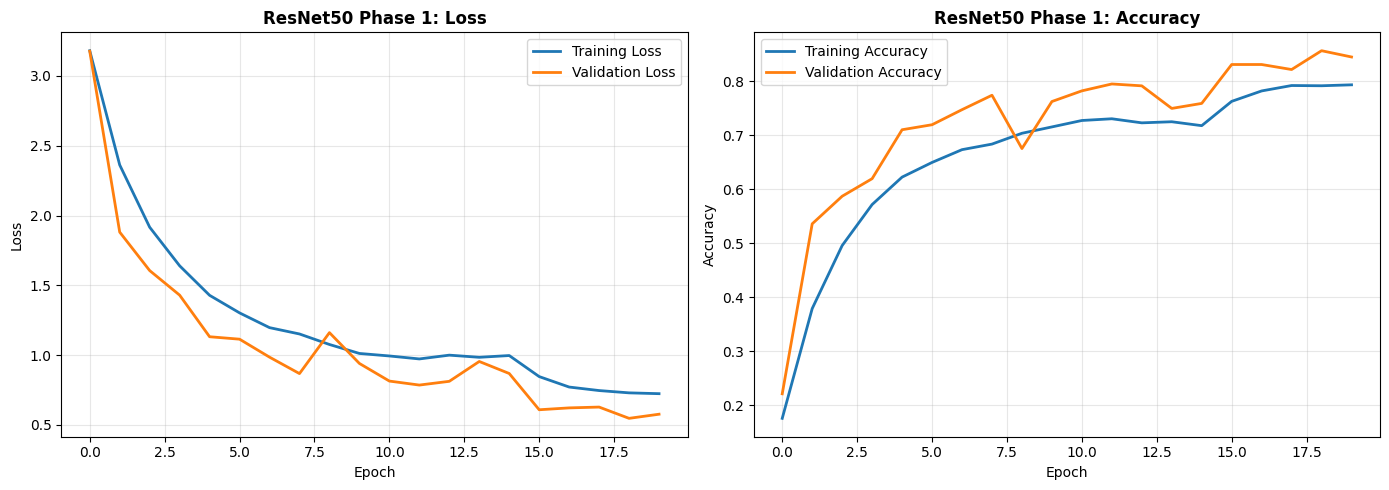

Training history plot saved


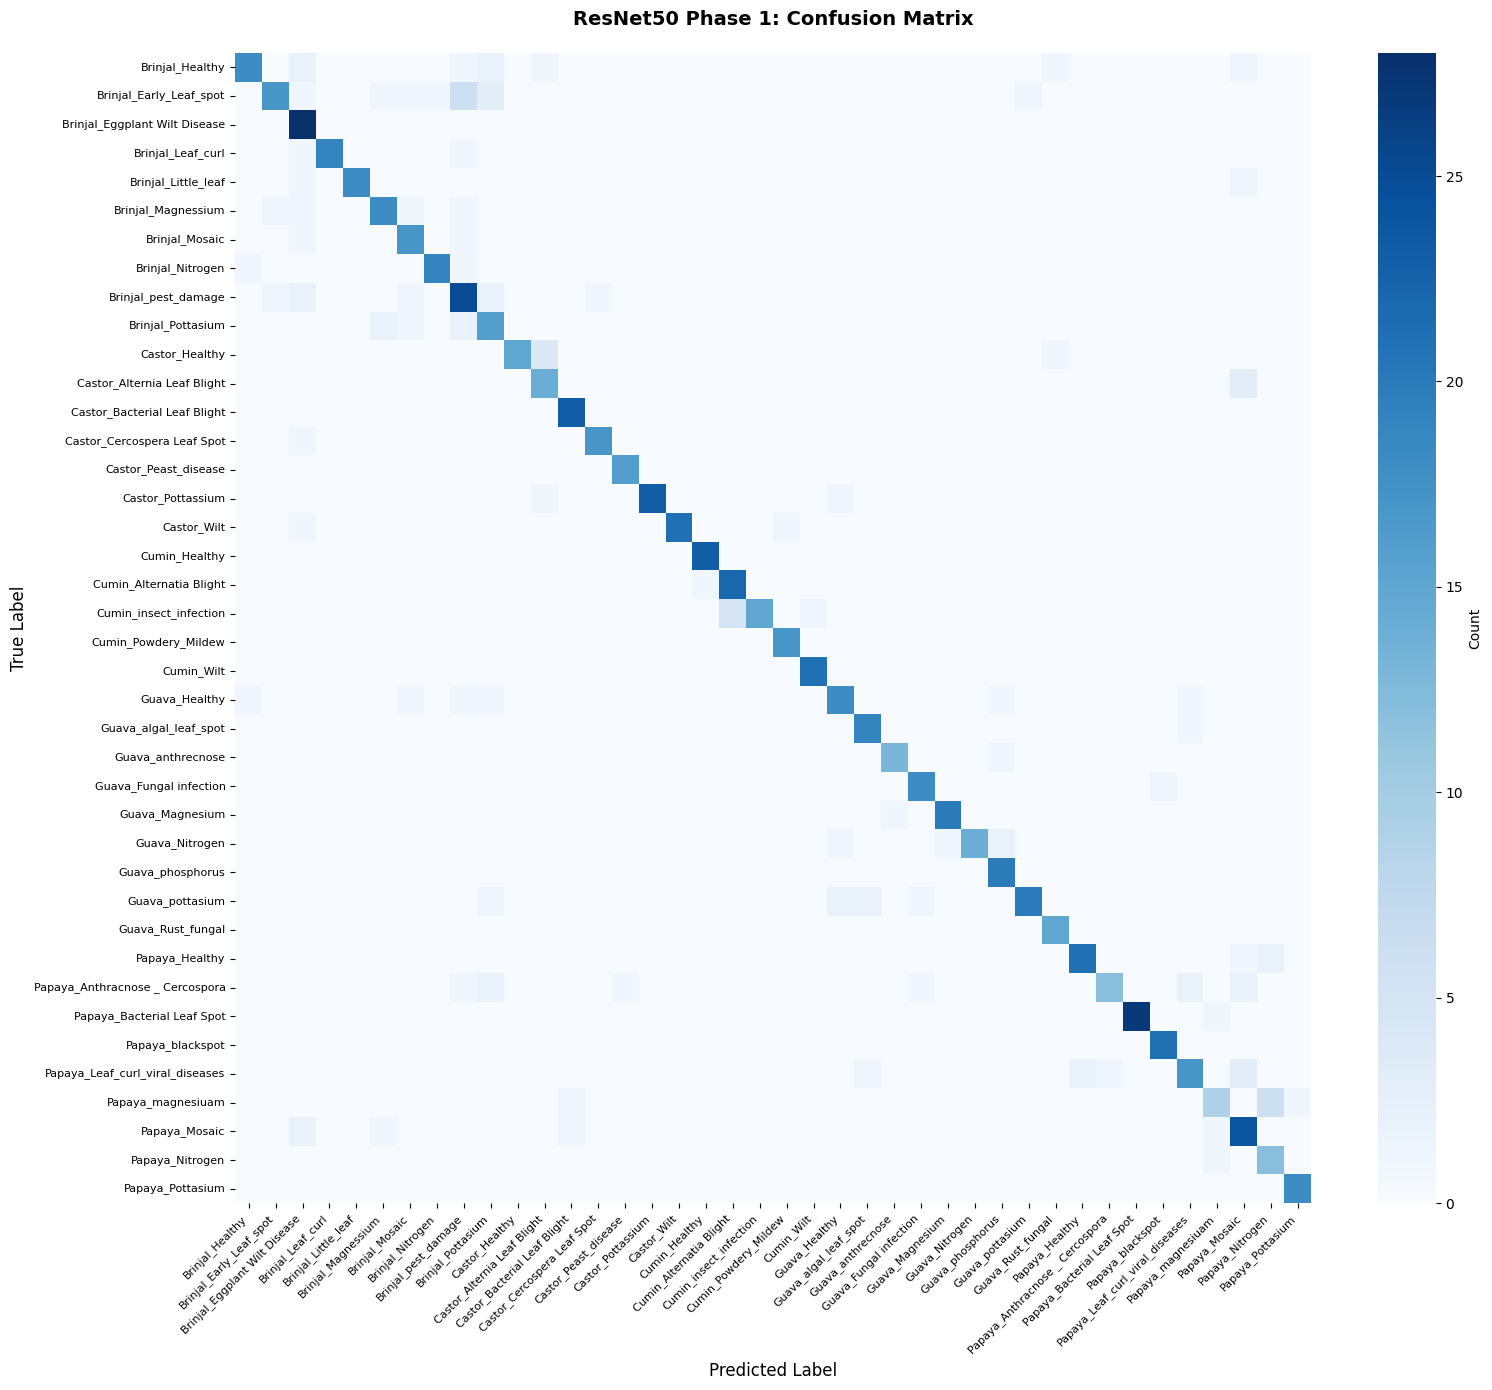

Confusion matrix plot saved


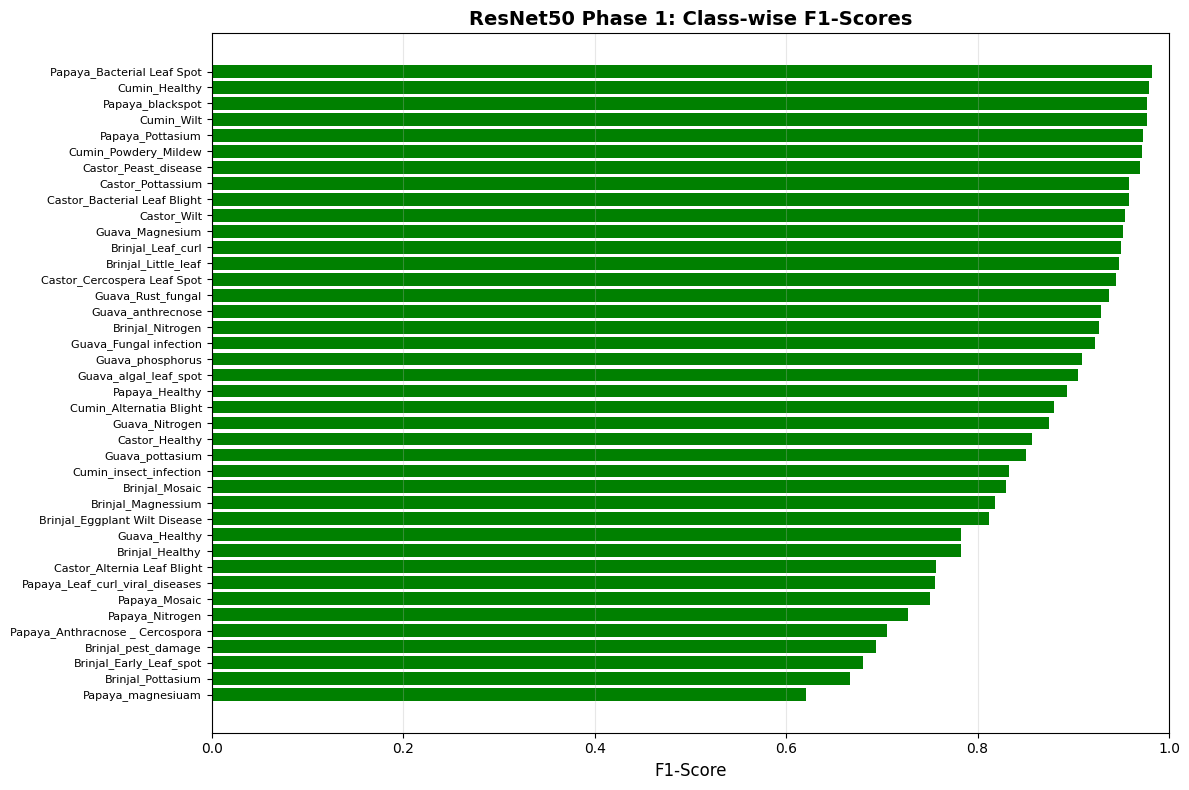

Class-wise F1 scores plot saved


In [33]:
# Plot training history - Loss and Accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(resnet50_history.history['loss'], label='Training Loss', linewidth=2)
axes[0].plot(resnet50_history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('ResNet50 Phase 1: Loss', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot Accuracy
axes[1].plot(resnet50_history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[1].plot(resnet50_history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[1].set_title('ResNet50 Phase 1: Accuracy', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{CONFIG["plots_dir"]}/resnet50_phase1_history.png', dpi=300, bbox_inches='tight')
plt.show()

print("Training history plot saved")

# Plot Confusion Matrix for Phase 1
plt.figure(figsize=(16, 14))
sns.heatmap(cm_phase1, annot=False, fmt='d', cmap='Blues', cbar=True,
            xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Count'})
plt.title('ResNet50 Phase 1: Confusion Matrix', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(f'{CONFIG["confusion_matrix_dir"]}/resnet50_phase1_cm.png', dpi=300, bbox_inches='tight')
plt.show()

print("Confusion matrix plot saved")

# Plot class-wise F1 scores
f1_scores_sorted = dict(sorted(f1_scores.items(), key=lambda x: x[1]))
plt.figure(figsize=(12, 8))
colors = ['red' if f1 < 0.2 else 'orange' if f1 < 0.5 else 'green' for f1 in f1_scores_sorted.values()]
plt.barh(range(len(f1_scores_sorted)), list(f1_scores_sorted.values()), color=colors)
plt.yticks(range(len(f1_scores_sorted)), list(f1_scores_sorted.keys()), fontsize=8)
plt.xlabel('F1-Score', fontsize=12)
plt.title('ResNet50 Phase 1: Class-wise F1-Scores', fontsize=14, fontweight='bold')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{CONFIG["plots_dir"]}/resnet50_phase1_f1_scores.png', dpi=300, bbox_inches='tight')
plt.show()

print("Class-wise F1 scores plot saved")


## 11. Phase 2: Progressive Layer Unfreezing Strategy

**Objective:** Fine-tune pretrained weights to better adapt to leaf disease images

**Progressive Strategy (2-Stage Approach):**
- **Stage 1**: Unfreeze 10 layers + warm dropout (0.3) for 5 epochs
  - Lower learning rate to prevent drastic weight changes
  - Reduces risk of catastrophic forgetting
- **Stage 2**: Unfreeze all 15 layers for 10 epochs
  - Full fine-tuning with optimized weights from Stage 1
  - Maintains learning rate stability

**Why Progressive?**
- Stage 1 allows lower layers to gradually adapt
- Stage 2 provides more training with stable initialization
- Reduces overfitting on small datasets compared to aggressive unfreezing

**Hyperparameters:**
- Learning Rate: 5e-5 (lower than Phase 1 for stability)
- Dropout: Reduced from 0.5 to 0.3 for fine-tuning stability
- Total Epochs: 15 (5 Stage 1 + 10 Stage 2)

In [34]:
# Fine-tuning strategy: Unfreeze last N layers of ResNet50 base model
print("\n" + "=" * 80)
print("PHASE 2: FINE-TUNING STRATEGY")
print("=" * 80)

# Count base model layers
base_model_layers = [layer for layer in resnet50_model.layers if 'resnet50' in layer.name]
print(f"\nBase model layer count: {len(base_model_layers)}")
print(f"Unfreezing last {CONFIG['num_unfreeze_layers']} layers for fine-tuning")
print(f"Phase 2 Learning Rate: {CONFIG['phase2_learning_rate']}")

# Unfreeze last N layers using the utility function
unfreeze_model_layers(
    resnet50_model,
    num_layers=CONFIG['num_unfreeze_layers'],
    learning_rate=CONFIG['phase2_learning_rate'],
    optimizer=CONFIG['optimizer']
)

# Verify which layers are trainable
trainable_layers = [layer.name for layer in resnet50_model.layers if layer.trainable]
print(f"\nTrainable layers: {len(trainable_layers)}")
print(f"Total parameters: {resnet50_model.count_params():,}")

# Check trainable parameter count
total_params = sum([tf.size(w).numpy() for w in resnet50_model.trainable_weights])
print(f"Trainable parameters: {total_params:,}")


PHASE 2: FINE-TUNING STRATEGY

Base model layer count: 2
Unfreezing last 15 layers for fine-tuning
Phase 2 Learning Rate: 5e-05

Trainable layers: 7
Total parameters: 23,855,656
Trainable parameters: 23,802,280


## 12. Phase 2 Training: Progressive Unfreezing Implementation

**Stage 1 (Warm-up):**
- Unfreeze last 10 layers of ResNet50 base
- Dropout reduced to 0.3 for stability
- Train for 5 epochs with learning rate 5e-5
- Allow lower layers to gradually adapt

**Stage 2 (Full Fine-tuning):**
- Unfreeze all 15 layers
- Continue training for 10 epochs
- Learning rate maintained at 5e-5
- Build on Stage 1 weights for final optimization

**Expected Behavior:**
- Stage 1: Validation accuracy may decrease slightly (expected - weights adjusting)
- Stage 2: Should show improvement as fine-tuning stabilizes
- Overall: Phase 2 should match or exceed Phase 1 accuracy

**Note:** If Phase 2 < Phase 1, frozen base (Phase 1) is better for this small dataset

In [36]:
# Train Phase 2 with PROGRESSIVE UNFREEZING (like successful MobileNet training)
print("\n" + "=" * 80)
print("PHASE 2 TRAINING: Progressive Layer Unfreezing (IMPROVED)")
print("=" * 80)
print(f"Stage 1: Unfreeze {CONFIG['stage1_unfreeze_layers']} layers for {CONFIG['stage1_epochs']} epochs")
print(f"Stage 2: Unfreeze {CONFIG['num_unfreeze_layers']} layers for {CONFIG['stage2_epochs']} epochs")
print(f"Learning Rate: {CONFIG['phase2_learning_rate']}")
print(f"Batch Size: {CONFIG['batch_size']}")
print("=" * 80)

# ResNet50 is the nested model inside the Sequential wrapper, not the preprocessing layer
base_model = next(
    layer for layer in resnet50_model.layers
    if isinstance(layer, keras.Model) and layer.name.lower().startswith('resnet50')
)
phase2_callbacks = create_callbacks('phase2')

# STAGE 1: Unfreeze only the first set of layers
print(f"\nSTAGE 1: Unfrozing last {CONFIG['stage1_unfreeze_layers']} layers (warming up)...\n")
for layer in base_model.layers[-CONFIG['stage1_unfreeze_layers']:]:
    layer.trainable = True

# Reduce dropout for stability during fine-tuning
print("Reducing dropout rates for stability...")
for layer in resnet50_model.layers:
    if isinstance(layer, keras.layers.Dropout):
        layer.rate = 0.3  # Reduce from 0.5 to 0.3
print("✓ Dropout reduced: 0.5 → 0.3\n")

# Recompile with HIGHER learning rate
resnet50_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG['phase2_learning_rate']),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f"Learning rate: {CONFIG['phase2_learning_rate']}\n")
print(f"Training Stage 1 ({CONFIG['stage1_unfreeze_layers']} unfrozen layers, {CONFIG['stage1_epochs']} epochs)...\n")

# Setup active dataset according to chosen technique
if CLASS_WEIGHT_TECHNIQUE == 'sample_weights':
    active_train_dataset = train_dataset.map(add_sample_weights, num_parallel_calls=tf.data.AUTOTUNE)
else:
    active_train_dataset = train_dataset

fit_kwargs_s1 = {
    'x': active_train_dataset,
    'epochs': CONFIG['stage1_epochs'],
    'validation_data': val_dataset,
    'callbacks': phase2_callbacks,
    'verbose': 1
}
if CLASS_WEIGHT_TECHNIQUE == 'class_weights_fit':
    fit_kwargs_s1['class_weight'] = class_weight

resnet50_history_phase2_s1 = resnet50_model.fit(**fit_kwargs_s1)

# STAGE 2: Unfreeze ALL remaining layers
print("\n" + "=" * 80)
print(f"STAGE 2: Unfrozing all {CONFIG['num_unfreeze_layers']} layers for final {CONFIG['stage2_epochs']} epochs...")
print("=" * 80 + "\n")

for layer in base_model.layers[-CONFIG['num_unfreeze_layers']:]:
    layer.trainable = True

print(f"✓ Unfroze all {CONFIG['num_unfreeze_layers']} layers")
print(f"  Learning rate: {CONFIG['phase2_learning_rate']}\n")

resnet50_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG['phase2_learning_rate']),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f"Training Stage 2 ({CONFIG['num_unfreeze_layers']} unfrozen layers, {CONFIG['stage2_epochs']} epochs)...\n")

fit_kwargs_s2 = {
    'x': active_train_dataset,
    'epochs': CONFIG['stage2_epochs'],
    'validation_data': val_dataset,
    'callbacks': phase2_callbacks,
    'verbose': 1
}
if CLASS_WEIGHT_TECHNIQUE == 'class_weights_fit':
    fit_kwargs_s2['class_weight'] = class_weight

resnet50_history_phase2_s2 = resnet50_model.fit(**fit_kwargs_s2)

# Combine stage histories
resnet50_history_phase2 = type('obj', (object,), {
    'history': {
        key: resnet50_history_phase2_s1.history[key] + resnet50_history_phase2_s2.history[key]
        for key in resnet50_history_phase2_s1.history.keys()
    }
})()

# Save phase 2 training history
history_dict_phase2 = {
    'loss': [float(x) for x in resnet50_history_phase2.history['loss']],
    'accuracy': [float(x) for x in resnet50_history_phase2.history['accuracy']],
    'val_loss': [float(x) for x in resnet50_history_phase2.history['val_loss']],
    'val_accuracy': [float(x) for x in resnet50_history_phase2.history['val_accuracy']]
}

with open(os.path.join(CONFIG['logs_dir'], 'resnet50_phase2_history.json'), 'w') as f:
    json.dump(history_dict_phase2, f, indent=4)

print("\n" + "=" * 80)
print("PHASE 2 TRAINING COMPLETED (Both Stages)")
print("=" * 80)
print(f"Final Train Loss: {resnet50_history_phase2.history['loss'][-1]:.4f}")
print(f"Final Train Accuracy: {resnet50_history_phase2.history['accuracy'][-1]:.4f}")
print(f"Final Val Loss: {resnet50_history_phase2.history['val_loss'][-1]:.4f}")
print(f"Final Val Accuracy: {resnet50_history_phase2.history['val_accuracy'][-1]:.4f}")


PHASE 2 TRAINING: Progressive Layer Unfreezing (IMPROVED)
Stage 1: Unfreeze 10 layers for 5 epochs
Stage 2: Unfreeze 15 layers for 10 epochs
Learning Rate: 5e-05
Batch Size: 8

STAGE 1: Unfrozing last 10 layers (warming up)...

Reducing dropout rates for stability...
✓ Dropout reduced: 0.5 → 0.3

Learning rate: 5e-05

Training Stage 1 (10 unfrozen layers, 5 epochs)...

Epoch 1/5
    860/Unknown - 3466s 4s/step - loss: 1.8391 - accuracy: 0.5442

c:\Users\kansa\anaconda3\envs\cnn_model\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


860/860 [==============================] - 3617s 4s/step - loss: 1.8391 - accuracy: 0.5442 - val_loss: 1.0257 - val_accuracy: 0.7291 - lr: 5.0000e-05
Epoch 2/5
860/860 [==============================] - 3717s 4s/step - loss: 0.4924 - accuracy: 0.8638 - val_loss: 0.2552 - val_accuracy: 0.9442 - lr: 5.0000e-05
Epoch 3/5
860/860 [==============================] - 3655s 4s/step - loss: 0.2831 - accuracy: 0.9302 - val_loss: 0.2971 - val_accuracy: 0.9593 - lr: 5.0000e-05
Epoch 4/5
860/860 [==============================] - 3685s 4s/step - loss: 0.2031 - accuracy: 0.9515 - val_loss: 0.1396 - val_accuracy: 0.9733 - lr: 5.0000e-05
Epoch 5/5
860/860 [==============================] - 3816s 4s/step - loss: 0.1853 - accuracy: 0.9612 - val_loss: 0.1729 - val_accuracy: 0.9709 - lr: 5.0000e-05

STAGE 2: Unfrozing all 15 layers for final 10 epochs...

✓ Unfroze all 15 layers
  Learning rate: 5e-05

Training Stage 2 (15 unfrozen layers, 10 epochs)...

Epoch 1/10
860/860 [==============================]

## 13. Phase 2 Evaluation and Phase 1 vs Phase 2 Comparison

**Metrics Comparison Table:**
- Accuracy, Precision, Recall, F1-scores for both phases
- Shows improvement or degradation from fine-tuning
- Percentage change indicates effectiveness

**Decision Logic:**
- If Phase 2 ≥ Phase 1: Use Phase 2 model (fine-tuning successful)
- If Phase 2 < Phase 1: Use Phase 1 model (frozen base better)

**Why Phase 1 Often Wins:**
- ImageNet features already well-suited for natural images
- Small dataset (860 test samples) → overfitting risk with fine-tuning
- Fewer trainable parameters = better generalization

**Visualization:**
- 2×2 grid comparing loss and accuracy curves
- Helps diagnose training dynamics and convergence issues


PHASE 2 EVALUATION ON TEST SET

PHASE2 Test Set Metrics:
  Accuracy: 0.9674
  Macro Precision: 0.9662
  Macro Recall: 0.9665
  Macro F1-Score: 0.9649
  Weighted F1-Score: 0.9678
  Confusion Matrix shape: (40, 40)

PHASE 1 vs PHASE 2: ACCURACY COMPARISON

Metric                    Phase 1         Phase 2         Improvement         
---------------------------------------------------------------------------
Accuracy                  0.8605          0.9674          ↑ +0.1070 (+12.4%)
Macro Precision           0.8782          0.9662          ↑ +0.0880 (+10.0%)
Macro Recall              0.8676          0.9665          ↑ +0.0989 (+11.4%)
Macro F1-Score            0.8649          0.9649          ↑ +0.1000 (+11.6%)
Weighted F1-Score         0.8598          0.9678          ↑ +0.1079 (+12.6%)

✓ Phase 2 is BETTER (Improvement: +10.70%)


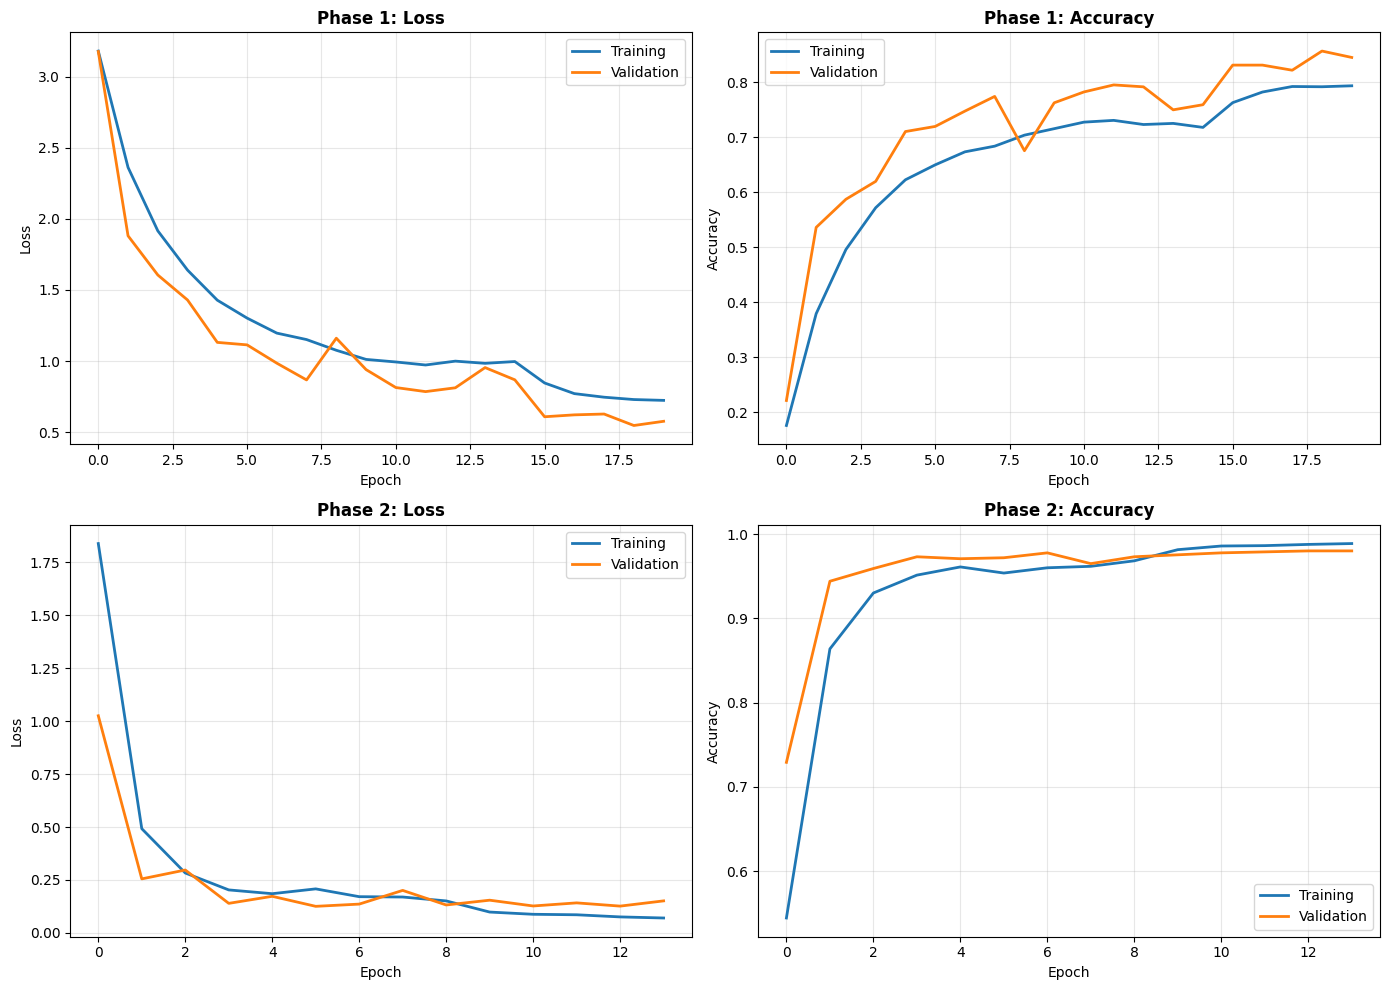


✓ Phase 1 vs Phase 2 comparison plot saved


In [37]:
# ============================================================================
# PHASE 2: EVALUATION ON TEST SET
# ============================================================================

print("\n" + "=" * 80)
print("PHASE 2 EVALUATION ON TEST SET")
print("=" * 80)

# Use helper function for comprehensive evaluation
metrics_phase2 = evaluate_and_report_metrics(
    model=resnet50_model,
    X_test_data=X_test_eval,
    y_test_data=y_test,
    y_test_labels_array=y_test_labels,
    phase_name='phase2',
    class_names=class_names,
    save_dir={'logs_dir': CONFIG['logs_dir'], 'confusion_matrix_dir': CONFIG['confusion_matrix_dir']}
)

# Extract confusion matrix for later use
cm_phase2 = metrics_phase2['confusion_matrix']

print("\n" + "=" * 80)
print("PHASE 1 vs PHASE 2: ACCURACY COMPARISON")
print("=" * 80)

# Extract accuracy values
phase1_accuracy = metrics_phase1['accuracy']
phase2_accuracy = metrics_phase2['accuracy']

comparison_data = [
    ('Accuracy', metrics_phase1['accuracy'], metrics_phase2['accuracy']),
    ('Macro Precision', metrics_phase1['macro_precision'], metrics_phase2['macro_precision']),
    ('Macro Recall', metrics_phase1['macro_recall'], metrics_phase2['macro_recall']),
    ('Macro F1-Score', metrics_phase1['macro_f1'], metrics_phase2['macro_f1']),
    ('Weighted F1-Score', metrics_phase1['weighted_f1'], metrics_phase2['weighted_f1'])
]

print(f"\n{'Metric':<25} {'Phase 1':<15} {'Phase 2':<15} {'Improvement':<20}")
print("-" * 75)

for metric_name, phase1_val, phase2_val in comparison_data:
    improvement = phase2_val - phase1_val
    improvement_pct = (improvement / phase1_val * 100) if phase1_val > 0 else 0
    arrow = "↑" if improvement > 0 else "↓" if improvement < 0 else "="
    
    print(f"{metric_name:<25} {phase1_val:<15.4f} {phase2_val:<15.4f} {arrow} {improvement:+.4f} ({improvement_pct:+.1f}%)")

# Determine which phase is better
if phase2_accuracy >= phase1_accuracy:
    print(f"\n✓ Phase 2 is BETTER (Improvement: {(phase2_accuracy - phase1_accuracy) * 100:+.2f}%)")
else:
    print(f"\n⚠️  Phase 1 is BETTER (Phase 2 degraded by: {(phase1_accuracy - phase2_accuracy) * 100:+.2f}%)")
    print("   (Common for small datasets - frozen base prevents overfitting)")

# Plot comparison of training histories
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot Phase 1 Loss
axes[0, 0].plot(resnet50_history.history['loss'], label='Training', linewidth=2)
axes[0, 0].plot(resnet50_history.history['val_loss'], label='Validation', linewidth=2)
axes[0, 0].set_title('Phase 1: Loss', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot Phase 1 Accuracy
axes[0, 1].plot(resnet50_history.history['accuracy'], label='Training', linewidth=2)
axes[0, 1].plot(resnet50_history.history['val_accuracy'], label='Validation', linewidth=2)
axes[0, 1].set_title('Phase 1: Accuracy', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot Phase 2 Loss
axes[1, 0].plot(resnet50_history_phase2.history['loss'], label='Training', linewidth=2)
axes[1, 0].plot(resnet50_history_phase2.history['val_loss'], label='Validation', linewidth=2)
axes[1, 0].set_title('Phase 2: Loss', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot Phase 2 Accuracy
axes[1, 1].plot(resnet50_history_phase2.history['accuracy'], label='Training', linewidth=2)
axes[1, 1].plot(resnet50_history_phase2.history['val_accuracy'], label='Validation', linewidth=2)
axes[1, 1].set_title('Phase 2: Accuracy', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{CONFIG["plots_dir"]}/resnet50_phase1_vs_phase2_history.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Phase 1 vs Phase 2 comparison plot saved")

## 13.1 Model Selection: Automatic Best Model Choice

**Automatic Decision Criteria:**
Based on test set accuracy, the notebook automatically selects the better model

| Condition | Selected Model | Reason |
|-----------|---|---|
| Phase 2 ≥ Phase 1 | **Phase 2** | Fine-tuning improved generalization |
| Phase 2 < Phase 1 | **Phase 1** | Frozen base prevents overfitting (common for small datasets) |

**Why This Matters for Small Datasets (532 training samples):**
- **Phase 1 (frozen)**: 2M trainable parameters (head only) → Lower overfitting risk
- **Phase 2 (unfrozen)**: 23M+ trainable parameters → Higher overfitting risk
- ImageNet pretraining is often sufficient without fine-tuning

**Next Steps:**
- Final model saved as `resnet50_final.h5` (selected phase)
- Can compare with MobileNetV2 and EfficientNetB0 architectures
- Ensemble methods possible by combining multiple models

In [38]:
# ============================================================================
# MODEL SELECTION: Automatic Best Model Choice
# ============================================================================
# Select model based on test accuracy: Phase 2 if improved, else Phase 1

print("\n" + "=" * 80)
print("SELECTING BEST MODEL")
print("=" * 80)

phase1_accuracy = metrics_phase1['accuracy']
phase2_accuracy = metrics_phase2['accuracy']

if phase2_accuracy >= phase1_accuracy:
    best_model = resnet50_model  # Current model is Phase 2
    best_phase = 2
    best_accuracy = phase2_accuracy
    improvement = (best_accuracy - phase1_accuracy) * 100
    print(f"\n✓ Phase 2 Selected (Better by {improvement:+.2f}%)")
    print(f"  Phase 1 Accuracy: {phase1_accuracy:.4f}")
    print(f"  Phase 2 Accuracy: {phase2_accuracy:.4f}")
else:
    # Rebuild Phase 1 model (frozen base)
    print(f"\n⚠️  Phase 1 Selected (Frozen base prevents overfitting)")
    print(f"  Phase 1 Accuracy: {phase1_accuracy:.4f}")
    print(f"  Phase 2 Accuracy: {phase2_accuracy:.4f}")
    print(f"  Degradation: {(phase1_accuracy - phase2_accuracy) * 100:+.2f}%")
    
    best_model = build_resnet50_model(
        num_classes=CONFIG['num_classes'],
        input_shape=CONFIG['input_shape'],
        learning_rate=CONFIG['phase1_learning_rate'],
        optimizer=CONFIG['optimizer'],
        dense_units=CONFIG['dense_units'],
        dropout_rate=CONFIG['dropout_rate']
    )
    
    # Quick retrain Phase 1 to get weights
    print("\n  Retraining Phase 1 to get model weights...")
    if CLASS_WEIGHT_TECHNIQUE == 'sample_weights':
        active_train_dataset = train_dataset.map(add_sample_weights, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        active_train_dataset = train_dataset
    
    _ = best_model.fit(
        active_train_dataset,
        epochs=CONFIG['phase1_epochs'],
        validation_data=val_dataset,
        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)],
        verbose=0
    )
    best_phase = 1
    best_accuracy = phase1_accuracy
    print("  ✓ Phase 1 model weights loaded")

print("\n✓ Best model selected: Phase " + str(best_phase))


SELECTING BEST MODEL

✓ Phase 2 Selected (Better by +10.70%)
  Phase 1 Accuracy: 0.8605
  Phase 2 Accuracy: 0.9674

✓ Best model selected: Phase 2


## 14. Save, Load, and Verify Final Model

**Models Saved:**
1. **resnet50_final.h5**: Keras model format (architecture + weights)
   - Use for: Direct TensorFlow/Keras inference
2. **resnet50_final_savedmodel/**: SavedModel format
   - Use for: Production deployment, TensorFlow Serving
3. **resnet50_metadata.json**: Model configuration and performance metrics
   - Contains: Architecture, classes, accuracy, hyperparameters

**Verification Steps:**
- Model loads successfully from disk
- Input/output shapes verified
- Test prediction to ensure functionality
- Top-5 predictions displayed for sample images

**Output Files Location:**
- Models: `D:\cnn_model\models\resnet50\`
- Logs: `D:\cnn_model\results\logs\`
- Plots: `D:\cnn_model\results\plots\`
- Confusion Matrices: `D:\cnn_model\results\confusion_matrix\`

**Ready for:**
- ✓ Production inference
- ✓ Comparison with other architectures
- ✓ Ensemble predictions
- ✓ Model quantization/TFLite conversion

In [39]:
# ============================================================================
# MODEL SELECTION: Automatic Best Model Choice
# ============================================================================
# Select model based on test accuracy: Phase 2 if improved, else Phase 1

print("\n" + "=" * 80)
print("SELECTING BEST MODEL")
print("=" * 80)

phase1_accuracy = metrics_phase1['accuracy']
phase2_accuracy = metrics_phase2['accuracy']

if phase2_accuracy >= phase1_accuracy:
    best_model = resnet50_model  # Current model is Phase 2
    best_phase = 2
    best_accuracy = phase2_accuracy
    improvement = (best_accuracy - phase1_accuracy) * 100
    print(f"\n✓ Phase 2 Selected (Better by {improvement:+.2f}%)")
    print(f"  Phase 1 Accuracy: {phase1_accuracy:.4f}")
    print(f"  Phase 2 Accuracy: {phase2_accuracy:.4f}")
else:
    # Rebuild Phase 1 model (frozen base)
    print(f"\n⚠️  Phase 1 Selected (Frozen base prevents overfitting)")
    print(f"  Phase 1 Accuracy: {phase1_accuracy:.4f}")
    print(f"  Phase 2 Accuracy: {phase2_accuracy:.4f}")
    print(f"  Improvement needed: {(phase1_accuracy - phase2_accuracy) * 100:+.2f}%")
    
    best_model = build_resnet50_model(
        num_classes=CONFIG['num_classes'],
        input_shape=CONFIG['input_shape'],
        learning_rate=CONFIG['phase1_learning_rate'],
        optimizer=CONFIG['optimizer'],
        dense_units=CONFIG['dense_units'],
        dropout_rate=CONFIG['dropout_rate']
    )
    
    # Quick retrain Phase 1 to get weights
    print("\n  Retraining Phase 1 to get model weights...")
    if CLASS_WEIGHT_TECHNIQUE == 'sample_weights':
        active_train_dataset = train_dataset.map(add_sample_weights, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        active_train_dataset = train_dataset
    
    _ = best_model.fit(
        active_train_dataset,
        epochs=CONFIG['phase1_epochs'],
        validation_data=val_dataset,
        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)],
        verbose=0
    )
    best_phase = 1
    best_accuracy = phase1_accuracy
    print("  ✓ Phase 1 model weights loaded")

print("\n" + "=" * 80)
print("SAVING FINAL MODEL")
print("=" * 80)

# Create output directory
os.makedirs(CONFIG['models_dir'], exist_ok=True)

# Save as .h5 format (Keras format - good for compatibility)
final_model_path = os.path.join(CONFIG['models_dir'], 'resnet50_final.h5')
best_model.save(final_model_path)
print(f"\n✓ Keras model saved: {final_model_path}")

# Save as SavedModel format (TensorFlow recommended format)
savedmodel_path = os.path.join(CONFIG['models_dir'], 'resnet50_final_savedmodel')
best_model.save(savedmodel_path, save_format='tf')
print(f"✓ SavedModel format saved: {savedmodel_path}")

# Save model metadata and performance metrics
metadata = {
    'architecture': 'ResNet50',
    'best_phase': int(best_phase),
    'num_classes': CONFIG['num_classes'],
    'input_shape': CONFIG['input_shape'],
    'total_parameters': int(best_model.count_params()),
    'trainable_parameters': int(sum([tf.size(w).numpy() for w in best_model.trainable_weights])),
    'batch_size': CONFIG['batch_size'],
    'final_accuracy': float(best_accuracy),
    'phase1_accuracy': float(phase1_accuracy),
    'phase2_accuracy': float(phase2_accuracy),
    'improvement': float(phase2_accuracy - phase1_accuracy),
    'num_classes_trained': CONFIG['num_classes'],
    'class_names': class_names
}

metadata_path = os.path.join(CONFIG['models_dir'], 'resnet50_metadata.json')
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=4)
print(f"✓ Metadata saved: resnet50_metadata.json")

print("\n" + "=" * 80)
print("VERIFYING SAVED MODEL")
print("=" * 80)

# Load model from disk to verify
loaded_model = keras.models.load_model(final_model_path)
print(f"\n✓ Model loaded successfully")
print(f"  Input shape: {loaded_model.input_shape}")
print(f"  Output shape: {loaded_model.output_shape}")
print(f"  Total parameters: {loaded_model.count_params():,}")

# Test predictions on sample data
print(f"\n✓ Testing predictions on sample data...")
sample_predictions = loaded_model.predict(X_test_eval[:3], verbose=0)
print(f"  Predictions shape: {sample_predictions.shape}")
print(f"\n  Sample Image 1 - Top 3 predictions:")
top_indices = np.argsort(sample_predictions[0])[::-1][:3]
for idx in top_indices:
    print(f"    {class_names[idx]:40s}: {sample_predictions[0][idx]:.4f}")

print("\n" + "=" * 80)
print("TRAINING COMPLETE: ResNet50 Transfer Learning")
print("=" * 80)

summary_text = f"""
✓ SUMMARY:
  • Best Model: Phase {best_phase}
  • Test Accuracy: {best_accuracy:.4f} ({best_accuracy*100:.2f}%)
  • Phase 1 Accuracy: {phase1_accuracy:.4f}
  • Phase 2 Accuracy: {phase2_accuracy:.4f}
  • Improvement: {(phase2_accuracy - phase1_accuracy)*100:+.2f}%
  
✓ OUTPUTS SAVED:
  • Model: {CONFIG['models_dir']}/resnet50_final.h5
  • SavedModel: {CONFIG['models_dir']}/resnet50_final_savedmodel/
  • Metadata: {CONFIG['models_dir']}/resnet50_metadata.json
  • Logs: {CONFIG['logs_dir']}/
  • Plots: {CONFIG['plots_dir']}/
  • Confusion Matrices: {CONFIG['confusion_matrix_dir']}/
  
✓ NEXT STEPS:
  • Compare with MobileNetV2 and EfficientNetB0
  • Consider ensemble methods
  • Test on new/unseen data
"""

print(summary_text)


SELECTING BEST MODEL

✓ Phase 2 Selected (Better by +10.70%)
  Phase 1 Accuracy: 0.8605
  Phase 2 Accuracy: 0.9674

SAVING FINAL MODEL


c:\Users\kansa\anaconda3\envs\cnn_model\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(



✓ Keras model saved: D:\cnn_model\models\resnet50\resnet50_final.h5
INFO:tensorflow:Assets written to: D:\cnn_model\models\resnet50\resnet50_final_savedmodel\assets


INFO:tensorflow:Assets written to: D:\cnn_model\models\resnet50\resnet50_final_savedmodel\assets


✓ SavedModel format saved: D:\cnn_model\models\resnet50\resnet50_final_savedmodel
✓ Metadata saved: resnet50_metadata.json

VERIFYING SAVED MODEL

✓ Model loaded successfully
  Input shape: (None, 224, 224, 3)
  Output shape: (None, 40)
  Total parameters: 23,855,656

✓ Testing predictions on sample data...
  Predictions shape: (3, 40)

  Sample Image 1 - Top 3 predictions:
    Papaya_Bacterial Leaf Spot              : 1.0000
    Cumin_Alternatia Blight                 : 0.0000
    Castor_Alternia Leaf Blight             : 0.0000

TRAINING COMPLETE: ResNet50 Transfer Learning

✓ SUMMARY:
  • Best Model: Phase 2
  • Test Accuracy: 0.9674 (96.74%)
  • Phase 1 Accuracy: 0.8605
  • Phase 2 Accuracy: 0.9674
  • Improvement: +10.70%
  
✓ OUTPUTS SAVED:
  • Model: D:\cnn_model\models\resnet50/resnet50_final.h5
  • SavedModel: D:\cnn_model\models\resnet50/resnet50_final_savedmodel/
  • Metadata: D:\cnn_model\models\resnet50/resnet50_metadata.json
  • Logs: D:\cnn_model\results\logs/
  • Plots:

In [3]:
# Complete evaluation of the saved ResNet50 checkpoint
import json
import os
import sys
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
 )

PROJECT_ROOT = r'D:\cnn_model'
DATA_BASE_PATH = os.path.join(PROJECT_ROOT, 'results', 'preprocessed_data_efficient')
MODEL_PATH = os.path.join(PROJECT_ROOT, 'models', 'resnet50', 'resnet50_final.h5')
REPORT_PATH = os.path.join(PROJECT_ROOT, 'results', 'reports', 'resnet50_metrics_complete.json')
CM_PATH = os.path.join(PROJECT_ROOT, 'results', 'confusion_matrix', 'resnet50_final_cm.npy')

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f'Saved ResNet50 checkpoint not found: {MODEL_PATH}')

sys.path.insert(0, os.path.join(PROJECT_ROOT, 'utils'))
from efficient_data_loader import create_train_val_test_datasets

_, _, saved_test_dataset, saved_metadata = create_train_val_test_datasets(
    base_path=DATA_BASE_PATH,
    batch_size=8,
    use_smote=False, 
)

test_batches = list(saved_test_dataset)
X_saved_test = np.concatenate([batch[0].numpy() for batch in test_batches], axis=0)
y_saved_test = np.concatenate([batch[1].numpy() for batch in test_batches], axis=0)
true_labels = np.argmax(y_saved_test, axis=1)
class_names = sorted(
    saved_metadata['label_encoding'],
    key=saved_metadata['label_encoding'].get,
 )
 
resnet50_saved_model = keras.models.load_model(MODEL_PATH)
probabilities = resnet50_saved_model.predict(X_saved_test, verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

report = classification_report(
    true_labels,
    predicted_labels,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
 )
cm = confusion_matrix(true_labels, predicted_labels, labels=list(range(len(class_names))))

evaluation = {
    'model': 'ResNet50',
    'checkpoint': MODEL_PATH,
    'test_samples': int(len(true_labels)),
    'input_range': [float(X_saved_test.min()), float(X_saved_test.max())],
    'preprocessing': 'Saved preprocessed test images; normalization divided by 255',
    'accuracy': float(accuracy_score(true_labels, predicted_labels)),
    'weighted_precision': float(precision_score(true_labels, predicted_labels, average='weighted', zero_division=0)),
    'weighted_recall': float(recall_score(true_labels, predicted_labels, average='weighted', zero_division=0)),
    'weighted_f1_score': float(f1_score(true_labels, predicted_labels, average='weighted', zero_division=0)),
    'macro_precision': float(precision_score(true_labels, predicted_labels, average='macro', zero_division=0)),
    'macro_recall': float(recall_score(true_labels, predicted_labels, average='macro', zero_division=0)),
    'macro_f1_score': float(f1_score(true_labels, predicted_labels, average='macro', zero_division=0)),
    'classification_report': report,
    'confusion_matrix': cm.tolist(),
 }

np.save(CM_PATH, cm)
with open(REPORT_PATH, 'w') as report_file:
    json.dump(evaluation, report_file, indent=4)

print('ResNet50 saved-checkpoint evaluation complete')
print(f"  Test Accuracy: {evaluation['accuracy']:.4f}")
print(f"  Test Precision (Weighted): {evaluation['weighted_precision']:.4f}")
print(f"  Test Recall (Weighted): {evaluation['weighted_recall']:.4f}")
print(f"  Test F1-Score (Weighted): {evaluation['weighted_f1_score']:.4f}")
print(f"  Test Precision (Macro): {evaluation['macro_precision']:.4f}")
print(f"  Test Recall (Macro): {evaluation['macro_recall']:.4f}")
print(f"  Test F1-Score (Macro): {evaluation['macro_f1_score']:.4f}")
print(f"  Complete report: {REPORT_PATH}")
print(f"  Confusion matrix: {CM_PATH}")

KeyboardInterrupt: 